## Learning Objectives

- Define graph formally using mathematical notation G = (V, E)
- Classify graphs by type (directed, weighted, bipartite, multigraph)
- Implement graph creation, traversal, and analysis with NetworkX
- Extract co-occurrence graphs and dependency graphs from raw text
- Compute and interpret centrality measures (degree, betweenness, closeness, eigenvector, PageRank)
- Produce publication-quality static visualizations and interactive HTML graphs
- Export graphs to Gephi for further analysis

## What's a Graph?
### 1.1 Formal Definition

A **graph** G is a pair G = (V, E) where:
- **V** is a finite set of **vertices** (also called *nodes*)
- **E ⊆ V × V** is a set of **edges** (also called *links* or *arcs*)

An edge between vertex u and vertex v is written as (u, v).

**Example:**  
A social network where people are nodes and friendships are edges.  
V = {Alice, Bob, Carol, Dave}  
E = {(Alice, Bob), (Alice, Carol), (Bob, Dave)}


### 1.2 Graph Types

| Type | Definition | Example |
|------|-----------|---------|
| **Undirected** | (u,v) = (v,u); edges have no direction | Friendship network |
| **Directed (DiGraph)** | (u,v) ≠ (v,u); edges have direction | Twitter follow graph |
| **Weighted** | Each edge carries a numeric weight w(u,v) | Road network (km), co-occurrence (count) |
| **Multigraph** | Multiple edges allowed between the same pair | Knowledge graph (multiple relation types) |
| **Bipartite** | V = A ∪ B, edges only between A and B | User–movie ratings |
| **DAG** | Directed Acyclic Graph; no directed cycles | Task dependency graph, taxonomy |
| **Hypergraph** | An edge can connect more than 2 nodes | Group membership |

## Create your first Graph

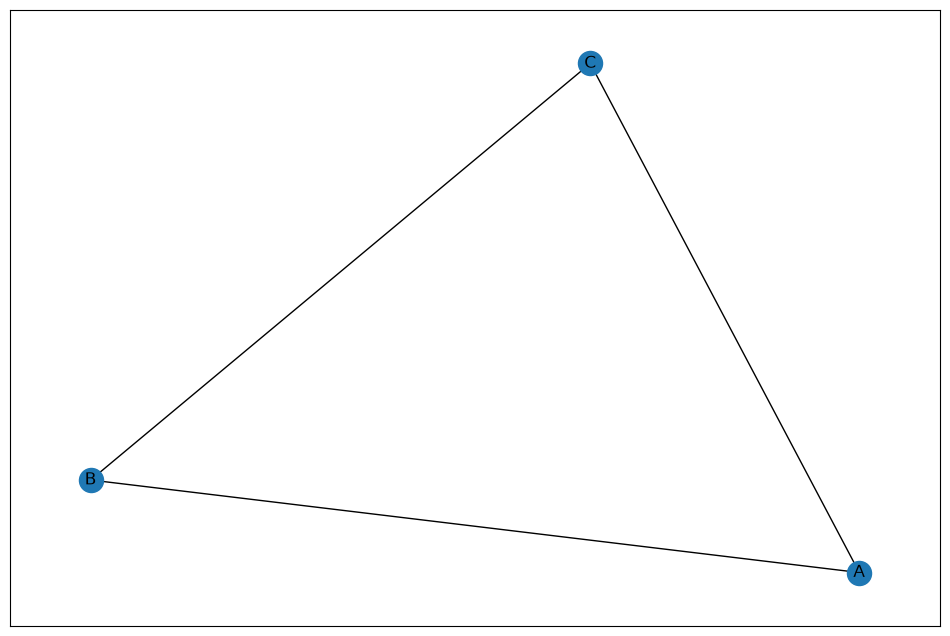

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
G = nx.Graph()

G.add_node("A")
G.add_nodes_from(["B", "C"])

G.add_edge("A", "B")
G.add_edges_from([("A", "C"), ("B", "C")])


plt.figure(figsize=(12, 8))
nx.draw_networkx(G)
plt.show()

- **figure()**: is to create a 12 by 8 inch figure, which will hold the visualization
- **draw_networkx()**: function uses Graph object G to produce visualization.
- **show()**: function renders the visualization, but can be omitted if we are running the examples in jupyter lab.


**Notes**:
- If we try to add an edge referring to a node ID that isn't in the network, NetworkX will automatically add the node
- In practice, we don't need to call add_node() directly.
- Check the following code:

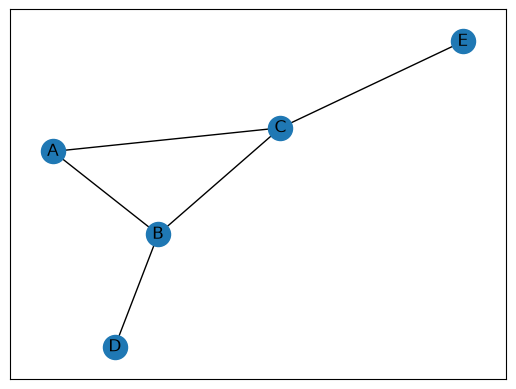

In [2]:
G.add_edges_from([("B", "D"), ("C", "E")])

nx.draw_networkx(G)

## Goal:
In this session, we will cover the following topics:
- **The graph Class**: Understand properties of undirected network and how they are represented using the NetworkX Graph class.
- **Attributes**: How to associate data with nodes and edges
- **Edge Weights**: Learn how to quantify connection strength, and annotate edges with that information.
- **The DiGraph Class**: Understand the properties of directed networks and how they are represented using the NetworkX DiGraph class.
- **The MultiGraph and MultiDiGraph classes**: Learn about networks with parallel edges.

## Create Undirected Graph using NetworkX python library

In [3]:
G = nx.Graph()

# Add Nodes
G.add_node("Bilal")
G.add_node("Ahmed")
G.add_node("Said")
G.add_node("Karim")
G.add_node("Ghita")


# Add Edges
G.add_edge("Bilal", "Ahmed")
G.add_edge("Bilal", "Ghita")
G.add_edge("Ahmed", "Karim")
G.add_edge("Karim", "Said")
G.add_edge("Karim", "Bilal")


In [4]:
print(f"Nodes ({G.number_of_nodes()}): {list(G.nodes())}")
print(f"Edges ({G.number_of_edges()}): {list(G.edges())}")

Nodes (5): ['Bilal', 'Ahmed', 'Said', 'Karim', 'Ghita']
Edges (5): [('Bilal', 'Ahmed'), ('Bilal', 'Ghita'), ('Bilal', 'Karim'), ('Ahmed', 'Karim'), ('Said', 'Karim')]


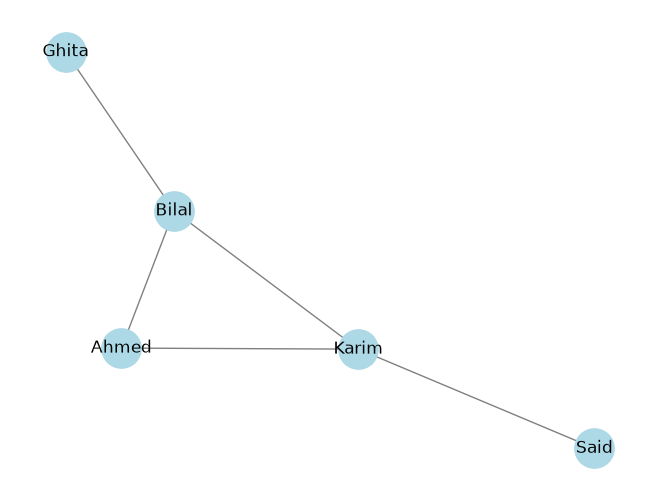

In [5]:
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', node_size=800)

### Add Nodes and Edges in Bulk

In [6]:
H = nx.Graph()

people = ["Alice", "Bob", "Carol", "Dave", "Eve", "Frank"]
H.add_nodes_from(people)

friendships = [
    ("Alice", "Bob"),
    ("Alice", "Carol"),
    ("Bob", "Dave"),
    ("Carol", "Dave"),
    ("Dave", "Eve"),
    ("Eve", "Frank"),
    ("Bob", "Frank"),
]
H.add_edges_from(friendships)

print(f"Nodes: {H.number_of_nodes()}, Edges: {H.number_of_edges()}")


Nodes: 6, Edges: 7


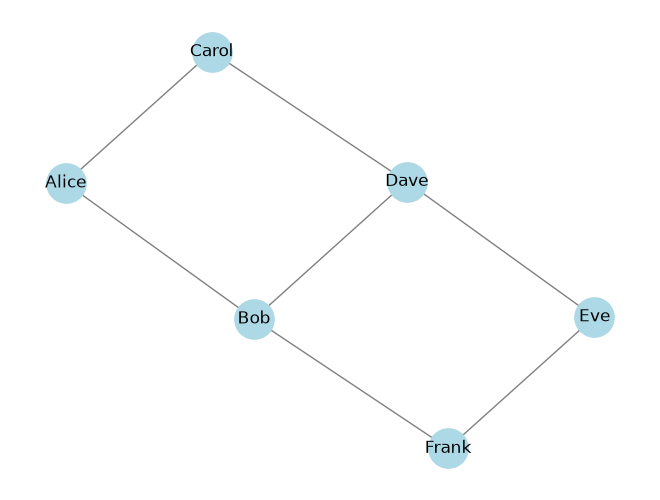

In [7]:
nx.draw(H, with_labels=True, node_color='lightblue', edge_color='gray', node_size=800)

### Create Directed Graph using NetworkX

In [8]:
DG = nx.DiGraph()

# Twitter-style follow graph
DG.add_edges_from([
    ("Alice", "Bob"),    # Alice follows Bob
    ("Alice", "Carol"),  # Alice follows Carol
    ("Bob", "Dave"),     # Bob follows Dave
    ("Carol", "Alice"),  # Carol follows Alice (mutual with Alice→Carol)
    ("Dave", "Alice"),
])

print("Successors of Alice (Alice follows):", list(DG.successors("Alice")))
print("Predecessors of Alice (who follows Alice):", list(DG.predecessors("Alice")))
print("In-degree of Alice:", DG.in_degree("Alice"))
print("Out-degree of Alice:", DG.out_degree("Alice"))

Successors of Alice (Alice follows): ['Bob', 'Carol']
Predecessors of Alice (who follows Alice): ['Carol', 'Dave']
In-degree of Alice: 2
Out-degree of Alice: 2


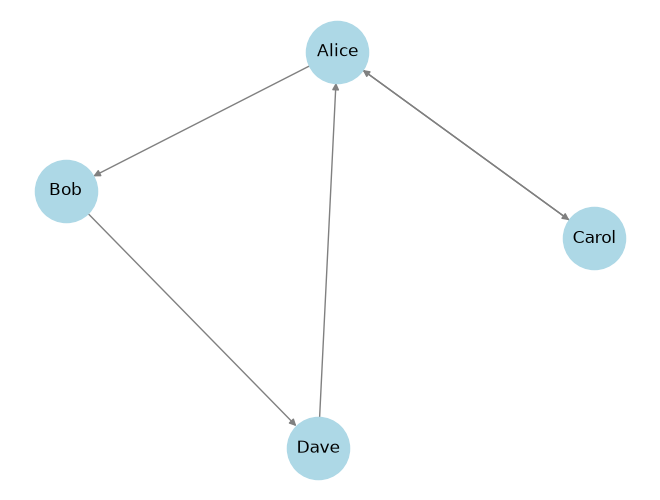

In [9]:
nx.draw(DG, with_labels=True, node_color='lightblue', edge_color='gray', node_size=2000)

### Create Weighted Graph using NetworkX

In [10]:
WG = nx.Graph()

# Read network: cities and distances

WG.add_edge("Paris", "Lyon",       weight=465)
WG.add_edge("Paris", "Marseille",  weight=775)
WG.add_edge("Lyon",  "Marseille",  weight=315)
WG.add_edge("Lyon",  "Bordeaux",   weight=560)
WG.add_edge("Paris", "Bordeaux",   weight=580)
WG.add_edge("Bordeaux", "Toulouse", weight=244)
WG.add_edge("Marseille", "Toulouse", weight=405)


{('Paris', 'Lyon'): Text(-0.3757921970720004, -0.5733343207013517, '465'),
 ('Paris', 'Marseille'): Text(0.2724777750026053, -0.3560695911645467, '775'),
 ('Paris',
  'Bordeaux'): Text(-0.25789834817727303, -0.16391367385746414, '580'),
 ('Lyon',
  'Marseille'): Text(-0.08201130992900696, -0.33608495999955856, '315'),
 ('Lyon', 'Bordeaux'): Text(-0.6123841214182728, -0.14392485312069203, '560'),
 ('Marseille',
  'Toulouse'): Text(0.6230390187376692, 0.44058868909094007, '405'),
 ('Bordeaux',
  'Toulouse'): Text(0.09266334905887852, 0.6327438509655334, '244')}

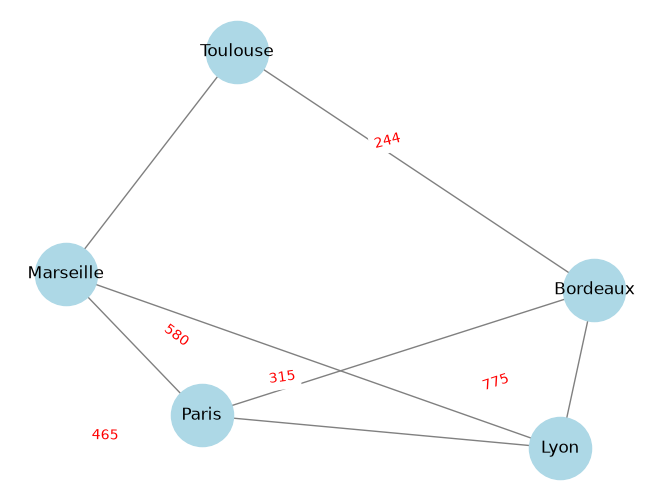

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

WG = nx.Graph()

# Read network: cities and distances
WG.add_edge("Paris", "Lyon",       weight=465)
WG.add_edge("Paris", "Marseille",  weight=775)
WG.add_edge("Lyon",  "Marseille",  weight=315)
WG.add_edge("Lyon",  "Bordeaux",   weight=560)
WG.add_edge("Paris", "Bordeaux",   weight=580)
WG.add_edge("Bordeaux", "Toulouse", weight=244)
WG.add_edge("Marseille", "Toulouse", weight=405)

# 1. Compute positions for the nodes (crucial for linking layouts)
pos = nx.spring_layout(WG, seed=42)  # seed keeps the layout consistent

# 2. Draw the base graph (nodes and edges)
nx.draw(WG, with_labels=True, node_color='lightblue', edge_color='gray', node_size=2000)

# 3. Pull the weight attributes into a dictionary
edge_labels = nx.get_edge_attributes(WG, 'weight')

# 4. Draw the edge labels onto the plot
nx.draw_networkx_edge_labels(WG, pos=pos,  edge_labels=edge_labels, font_color='red')



### Node Attributes

In [12]:
G2 = nx.Graph()

# Add nodes with attributes
G2.add_node("Alice",  age=30, department="CS",       role="Professor")
G2.add_node("Bob",    age=25, department="CS",       role="PhD Student")
G2.add_node("Carol",  age=28, department="Math",     role="Researcher")
G2.add_node("Dave",   age=32, department="Physics",  role="Professor")

# Add edges with attributes
G2.add_edge("Alice", "Bob",   relation="supervises", since=2022)
G2.add_edge("Alice", "Carol", relation="collaborates", papers=3)
G2.add_edge("Bob",   "Carol", relation="coauthors",  papers=1)
G2.add_edge("Carol", "Dave",  relation="collaborates", papers=2)

# Access attributes
print("Alice's attributes:", G2.nodes["Alice"])
print("Alice-Carol edge:", G2.edges["Alice", "Carol"])

# Filter nodes by attribute
professors = [n for n, d in G2.nodes(data=True) if d.get("role") == "Professor"]
print("Professors:", professors)

Alice's attributes: {'age': 30, 'department': 'CS', 'role': 'Professor'}
Alice-Carol edge: {'relation': 'collaborates', 'papers': 3}
Professors: ['Alice', 'Dave']


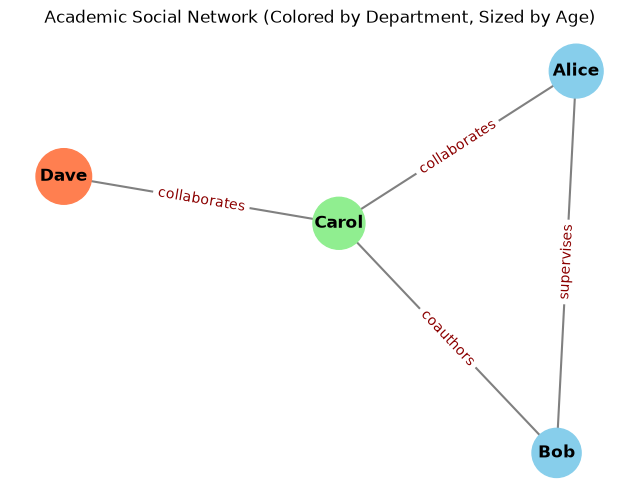

In [13]:
# 1. Define a color palette map for each department
color_map_dict = {"CS": "skyblue", "Math": "lightgreen", "Physics": "coral"}
node_colors = [color_map_dict[G2.nodes[node]["department"]] for node in G2.nodes]

# 2. Scale node size based on age (e.g., age * 50 to make it visually clear)
node_sizes = [G2.nodes[node]["age"] * 50 for node in G2.nodes]

# 3. Extract the relation attribute for the edge labels
edge_labels = nx.get_edge_attributes(G2, "relation")

# 4. Generate layout and plot graph elements
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G2, seed=42)

# Draw nodes with dynamic colors and sizes
nx.draw_networkx_nodes(G2, pos, node_color=node_colors, node_size=node_sizes)

# Draw edges and text labels
nx.draw_networkx_edges(G2, pos, edge_color="gray", width=1.5)
nx.draw_networkx_labels(G2, pos, font_size=12, font_weight="bold")
nx.draw_networkx_edge_labels(G2, pos, edge_labels=edge_labels, font_color="darkred")

# 5. Clean up layout and display
plt.title("Academic Social Network (Colored by Department, Sized by Age)")
plt.axis("off")
plt.show()


### MultiGraph
### What is MultiGraph
A **MultiGraph** is an **undirected graph** that relaxes two strict constraints found in a simple graph:

| Feature | `nx.Graph` | `nx.MultiGraph` |
|---|---|---|
| Self-loops (A → A) | ✅ Allowed | ✅ Allowed |
| Parallel edges (multiple edges between the same pair of nodes) | ❌ Not allowed | ✅ Allowed |
| Edge keys to distinguish parallel edges | ❌ No | ✅ Yes |

> **Definition:** A MultiGraph \( G = (V, E) \) where \( E \) is a **multiset** — the same pair of nodes can appear more than once.

### Core Concepts
- **Multiedge**: Multiple distinct edges connecting the same two nodes, each potentially carrying different attributes.
- **Self-loop**: An edge from a node to itself, i.e., (A, A).
- **Edge key**: An integer (or custom) identifier that distinguishes parallel edges between the same pair of nodes.
 

In [14]:
import networkx as nx

# Simple example: two people can have multiple kinds of relationships
G = nx.MultiGraph()
G.add_edge("Alice", "Bob", relation="friend")
G.add_edge("Alice", "Bob", relation="colleague")  # parallel edge!
G.add_edge("Alice", "Alice", relation="self-reflection")  # self-loop!

print(f"Edges: {list(G.edges(data=True, keys=True))}")


Edges: [('Alice', 'Bob', 0, {'relation': 'friend'}), ('Alice', 'Bob', 1, {'relation': 'colleague'}), ('Alice', 'Alice', 0, {'relation': 'self-reflection'})]


### When to choose MultiGraph?

Use **MultiGraph** when:

- Two entities can have multiple independent relationships (e.g., city pairs connected by multiple roads or flight routes).
- Edges represent different types of connections that must coexist (e.g., different protocols in a network).
- You model multigraphs from mathematics or chemistry (resonance structures, bond types).
- The order or history of connections matters (e.g., repeated transactions between bank accounts).

## Create MultiGraph

In [15]:
import networkx as nx

# Create an empty MultiGraph
G = nx.MultiGraph()
print(type(G))   # <class 'networkx.classes.multigraph.MultiGraph'>

<class 'networkx.classes.multigraph.MultiGraph'>


### MultiGraph with Graph Attributes

In [16]:
G = nx.MultiGraph(name="Transportation Network", year=2026)
print(G.graph)
# {'name': 'Transportation Network', 'year': 2026}


{'name': 'Transportation Network', 'year': 2026}


## Build MultiGraph from Edge list

In [ ]:
edges = [(1, 2), (1, 2), (2, 3), (3, 3)]  # includes parallel edge and self-loop
G = nx.MultiGraph(edges)
print(list(G.edges(keys=True)))


[(1, 2, 0), (1, 2, 1), (2, 3, 0), (3, 3, 0)]


## Build MultiGraph From an Existing Graph

In [ ]:
# Convert a simple path graph to a MultiGraph
H = nx.path_graph(5)           # 0-1-2-3-4
G = nx.MultiGraph(H)           # copy structure into MultiGraph
print(list(G.edges()))



[(0, 1), (1, 2), (2, 3), (3, 4)]


### Build MultiGraph From a Dictionary

In [19]:
# dict-of-dict-of-dict-of-dict (multigraph format)
data = {
    1: {2: {0: {"weight": 5}, 1: {"weight": 9}}},
    2: {3: {0: {"weight": 2}}}
}
G = nx.MultiGraph(data, multigraph_input=True)
print(G.number_of_edges())  # 3


3


## Adding and Removing Nodes
Nodes in a MultiGraph can be any hashable Python object: integers, strings, tuples, even other graphs.

### Adding Nodes

In [20]:
G = nx.MultiGraph()

# Add a single node
G.add_node("Paris")

# Add multiple nodes from a list
G.add_nodes_from(["London", "Berlin", "Rome"])

# Add nodes with attributes
G.add_node("Tokyo", population=14_000_000, continent="Asia")
G.add_nodes_from([("Cairo", {"population": 21_000_000}),
                  ("Sydney", {"population": 5_300_000})])

# Inspect nodes
print(list(G.nodes(data=True)))


[('Paris', {}), ('London', {}), ('Berlin', {}), ('Rome', {}), ('Tokyo', {'population': 14000000, 'continent': 'Asia'}), ('Cairo', {'population': 21000000}), ('Sydney', {'population': 5300000})]


### Nodes from Another Graph


In [22]:
H = nx.path_graph(5)   # nodes 0, 1, 2, 3, 4
G.add_nodes_from(H)    # imports only nodes
print(G.nodes())


['Paris', 'London', 'Berlin', 'Rome', 'Tokyo', 'Cairo', 'Sydney', 0, 1, 2, 3, 4]


## Remove Nodes


In [23]:
G.remove_node("Paris")              # remove one node (and all its edges)
G.remove_nodes_from(["London", "Berlin"])  # remove multiple

**Warning**: Removing a node also removes all edges incident to that node, including parallel edges and self-loops.

## Checking Node Existence

In [24]:
print("Tokyo" in G)            # True  — using __contains__
print(G.has_node("Tokyo"))     # True  — explicit method
print(G.has_node("Madrid"))    # False


True
True
False


## Add and Remove Edges
### Add a single Edge

In [25]:
G = nx.MultiGraph()

# Returns the edge KEY assigned to this edge
key = G.add_edge("A", "B")
print(key)   # 0  ← first edge gets key 0

key2 = G.add_edge("A", "B")   # parallel edge!
print(key2)  # 1  ← second edge gets key 1

key3 = G.add_edge("A", "B", weight=3.5, mode="express")
print(key3)  # 2

0
1
2


### Add Multiple Edges

In [26]:
# From a list of (u, v) tuples
keys = G.add_edges_from([("A", "C"), ("B", "C"), ("C", "D")])
print(keys)  # [0, 0, 0]

# From a list of (u, v, attr_dict) tuples
keys = G.add_edges_from([
    ("A", "B", {"route": 28, "type": "highway"}),
    ("A", "B", {"route": 37, "type": "secondary"}),
])
print(keys)  # [3, 4]  ← continues from where we left off


[0, 0, 0]
[3, 4]


### Add Weighted Edges

In [27]:
# Add edges with a 'weight' attribute directly
G = nx.MultiGraph()
G.add_weighted_edges_from([
    ("NYC", "LA", 2800),     # distance in miles
    ("NYC", "LA", 2850),     # different route, same cities!
    ("LA",  "SF", 380),
])
print(list(G.edges(data=True, keys=True)))


[('NYC', 'LA', 0, {'weight': 2800}), ('NYC', 'LA', 1, {'weight': 2850}), ('LA', 'SF', 0, {'weight': 380})]


### Self-loops


In [28]:
G = nx.MultiGraph()

# A node connected to itself
key = G.add_edge("A", "A", label="self-reference")
print(f"Self-loop key: {key}")
print(list(G.edges("A", keys=True, data=True)))


Self-loop key: 0
[('A', 'A', 0, {'label': 'self-reference'})]
